In [1]:
import pandas as pd
import numpy as np

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv'

In [3]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv'

In [4]:
df = pd.read_csv(data)

In [5]:
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [6]:
df.columns = df.columns.str.lower().str.replace(' ','_')

In [7]:
chaine  = list(df.dtypes[df.dtypes=='str'].index)
chaine

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [8]:
for col in chaine : 
    df[col]=df[col].str.lower().str.replace(' ','_')

In [9]:
df.head(n=2)

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650


In [10]:
for col in df.columns : 
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())

make
<StringArray>
['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
Length: 5, dtype: str
48
model
<StringArray>
['1_series_m', '1_series', '100', '124_spider', '190-class']
Length: 5, dtype: str
914
year
[2011 2012 2013 1992 1993]
28
engine_fuel_type
<StringArray>
[   'premium_unleaded_(required)',               'regular_unleaded',
 'premium_unleaded_(recommended)',       'flex-fuel_(unleaded/e85)',
                         'diesel']
Length: 5, dtype: str
10
engine_hp
[335. 300. 230. 320. 172.]
356
engine_cylinders
[ 6.  4.  5.  8. 12.]
9
transmission_type
<StringArray>
['manual', 'automatic', 'automated_manual', 'direct_drive', 'unknown']
Length: 5, dtype: str
5
driven_wheels
<StringArray>
['rear_wheel_drive', 'front_wheel_drive', 'all_wheel_drive',
 'four_wheel_drive']
Length: 4, dtype: str
4
number_of_doors
[ 2.  4.  3. nan]
3
market_category
<StringArray>
['factory_tuner,luxury,high-performance',
                    'luxury,performance',
               'luxury,high-performance

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns 
%matplotlib inline

<Axes: xlabel='msrp', ylabel='Count'>

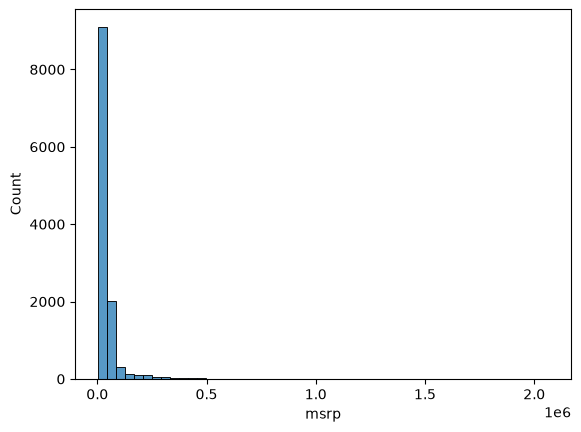

In [12]:
sns.histplot(df.msrp, bins=50)

<Axes: xlabel='msrp', ylabel='Count'>

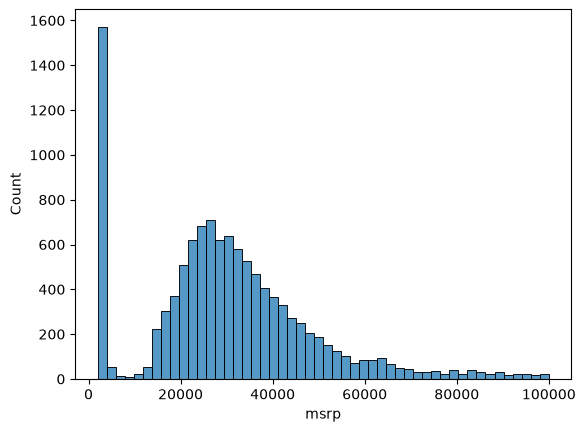

In [13]:
sns.histplot(df.msrp[df.msrp<100000],bins=50)

In [14]:
price_logs = np.log1p(df.msrp)

<Axes: xlabel='msrp', ylabel='Count'>

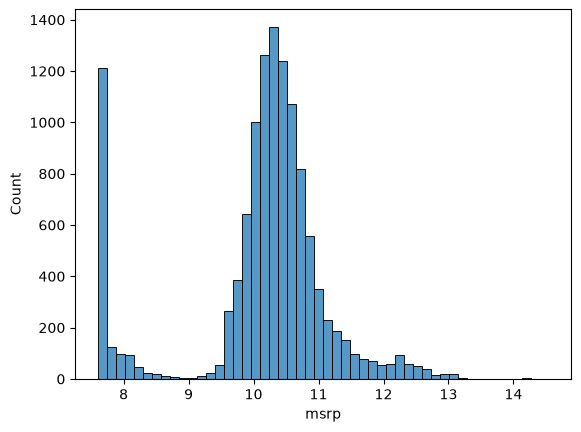

In [15]:
sns.histplot(price_logs,bins=50)

In [16]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

In [17]:
n = len(df)
n_val = int(0.2*n)
n_test = int(0.2*n)
n_train = n-n_test - n_val

In [18]:
n, n_val, n_test, n_train

(11914, 2382, 2382, 7150)

In [19]:
np.random.seed(2)
idx = np.arange(n)
np.random.shuffle(idx)

In [20]:
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]

In [21]:
len(df_train)

7150

In [22]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [23]:
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

In [24]:
del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

In [25]:
xi = [453, 11, 86]
w0 = 7.17
w = [0.01, 0.04, 0.002]

In [26]:
def linear_regression(xi) :
    n = len(xi)
    pred = w0 
    for j in range (n) : 
        pred = pred + w[j]*xi[j]

    return pred

In [27]:
linear_regression(xi)

12.312

In [28]:
np.expm1(linear_regression(xi))

np.float64(222347.2221101062)

In [29]:
def dot(xi,w) :
    n = len(xi)
    res = 0.0
    for j in range(n) : 
        res = res+ w[j] * xi[j]
    return res

In [30]:
def linear_regression2(xi) :
    return w0 + dot(xi,w)

In [31]:
linear_regression2(xi)

12.312000000000001

In [32]:
w_new = [w0] + w

In [33]:
def linear_regression3(xi) :
    xi = [1] + xi
    return dot(xi,w_new)

In [34]:
linear_regression3(xi)

12.312

In [35]:
x1  = [1, 148, 24, 1385]
x2  = [1, 132, 25, 2031]
x10 = [1, 453, 11, 86]
X= [x1,x2,x10]
X=np.array(X)

In [36]:
w0 = 7.17
w = [0.01, 0.04, 0.002]
w_new= [w0] +w

In [37]:
def linear_regression4(X) :
    return X.dot(w_new)

In [38]:
linear_regression4(X)

array([12.38 , 13.552, 12.312])

In [39]:
X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38,  54, 185],
    [142, 25, 431],
    [453, 31, 86],
]
X = np.array(X)
ones = np.ones(X.shape[0])
X=np.column_stack([ones,X])

In [40]:
XTX = X.T.dot(X)

In [41]:
XTX_inv = np.linalg.inv(XTX)

In [42]:
XTX.dot(XTX_inv).round(1)

array([[ 1., -0.,  0.,  0.],
       [-0.,  1.,  0., -0.],
       [-0.,  0.,  1.,  0.],
       [-0., -0.,  0.,  1.]])

In [43]:
y = [100, 200, 150, 250, 100, 200, 150, 250, 120]

In [44]:
w_full = XTX_inv.dot(X.T).dot(y)

In [45]:
w0 = w_full[0]
w = w_full[1:]

In [92]:
X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38,  54, 185],
    [142, 25, 431],
    [453, 31, 86],
]
X = np.array(X)
y = [100, 200, 150, 250, 100, 200, 150, 250, 120]

def train_regression(X,y,r=0.001) :
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones,X])
    XTX = X.T.dot(X)
    XTX= XTX + r *np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0],w_full[1:]


In [47]:
train_regression(X,y)

(np.float64(300.06776692555627),
 array([-0.22774253, -2.5769413 , -0.02301206]))

In [48]:
df_train.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity'],
      dtype='str')

In [49]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg',
        'city_mpg', 'popularity']

In [50]:
X_train =df_train[base].values

In [51]:
df_train[base].isnull().sum()

engine_hp           40
engine_cylinders    14
highway_mpg          0
city_mpg             0
popularity           0
dtype: int64

In [52]:
X_train= df_train[base].fillna(0).values

In [53]:
w0 ,w = train_regression(X_train,y_train)

In [54]:
y_pred = w0 + X_train.dot(w)

<Axes: ylabel='Count'>

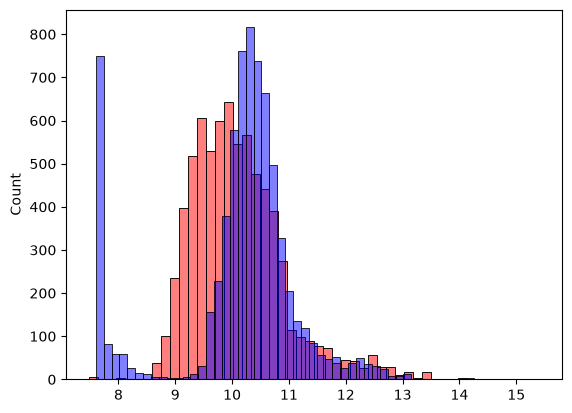

In [55]:
sns.histplot(y_pred,color='red' , alpha = 0.5 ,bins =50)
sns.histplot(y_train,color='blue' , alpha = 0.5 ,bins =50)

In [56]:
def rmse_error(y_pred,y_train) :
    error = y_pred - y_train

    se = error **2 
    mse = se.mean()
    return np.sqrt(mse)

In [57]:
rmse_error(y_pred,y_train)

np.float64(0.7554192603920132)

In [66]:
def prepare_x(df):

    df = df.copy()

    df['age'] = 2026 - df['year']
    features =  base + ['age']

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype('int')
        features.append('num_doors_%s' % v)
    
    df_num = df[features]

    df_num = df_num.fillna(0)
    X =df_num.values
    return X

In [67]:
X_train = prepare_x(df_train)
w0 , w = train_regression(X_train,y_train)

X_val = prepare_x(df_val)
y_pred = w0 + X_val.dot(w)

rmse_error(y_pred,y_val)

np.float64(0.5157995641502869)

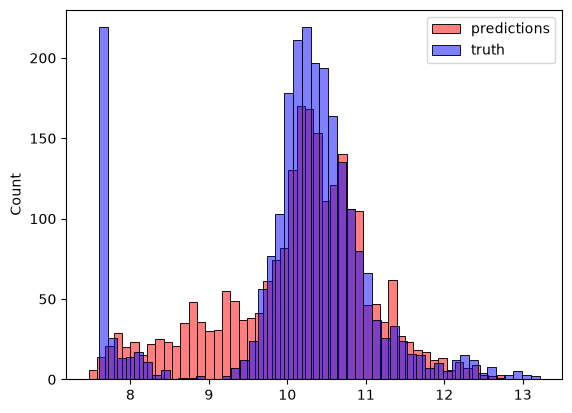

In [64]:
sns.histplot(y_pred,label='predictions' , color='red', alpha =0.5 , bins = 50)
sns.histplot(y_val,label='truth', color='blue',alpha=0.5,bins=50)
plt.legend()

In [ ]:
makes =list(df.make.value_counts().head().index)


['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge']

In [89]:
categorical_variables = [
    'make', 'engine_fuel_type', 'transmission_type', 'driven_wheels',
    'market_category', 'vehicle_size', 'vehicle_style'
]


categories ={}

for c in categorical_variables :
    categories[c]=list(df_train[c].value_counts().head().index)

In [90]:
def prepare_x(df):

    df = df.copy()

    df['age'] = 2026 - df['year']
    features =  base + ['age']

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype('int')
        features.append('num_doors_%s' % v)

    for c, values in categories.items():
        for v in values:
            df['%s_%s' % (c, v)] = (df[c] == v).astype('int')
            features.append('%s_%s' % (c, v))
        
    
    df_num = df[features]

    df_num = df_num.fillna(0)
    X =df_num.values
    return X

In [95]:


r=0.001
X_train = prepare_x(df_train)
w0 , w = train_regression(X_train,y_train, r=r)

X_val = prepare_x(df_val)
y_pred = w0 + X_val.dot(w)

score = rmse_error(y_pred,y_val)
score

np.float64(0.4565175975263901)

In [96]:
df_full_train = pd.concat([df_train,df_val])

In [97]:
df_full_train = df_full_train.reset_index(drop=True)

In [99]:
X_full_train = prepare_x(df_full_train)

In [101]:
y_full_train = np.concat([y_train,y_val])

In [102]:
w0 , w = train_regression(X_full_train,y_full_train)

In [104]:
X_test = prepare_x(df_test)
y_pred = w0 + X_test.dot(w)
score = rmse_error(y_pred,y_test)
score

np.float64(0.45177496201541456)

In [105]:
car = df_test.iloc[20].to_dict()
car

{'make': 'toyota',
 'model': 'sienna',
 'year': 2015,
 'engine_fuel_type': 'regular_unleaded',
 'engine_hp': 266.0,
 'engine_cylinders': 6.0,
 'transmission_type': 'automatic',
 'driven_wheels': 'front_wheel_drive',
 'number_of_doors': 4.0,
 'market_category': nan,
 'vehicle_size': 'large',
 'vehicle_style': 'passenger_minivan',
 'highway_mpg': 25,
 'city_mpg': 18,
 'popularity': 2031}

In [107]:
df_car = pd.DataFrame([car])
x_car = prepare_x(df_car)
y_pred = w0 + x_car.dot(w)
y_pred


array([10.46265049])

In [110]:
np.expm1(y_pred[0])

np.float64(34983.153905011786)